In [1]:
!git clone -q https://github.com/esa/SpOC2.git
%cd "/kaggle/working/SpOC2/Morphing Rovers"
!mkdir -p data/spoc2/morphing && cp -r data/Maps data/coordinates.txt data/example_rover.npy data/spoc2/morphing/
!sed -i "77s/.*/HEIGHTMAP_NAMES = ['Map1.jpg', 'Map2.jpg', 'Map3.jpg', 'Map4.jpg', 'Map5.jpg', 'Map6.jpg']/" morphing_udp.py
!sed -i '683s/, angle,/, float(angle),/' morphing_udp.py
!pip install -q cma

/kaggle/working/SpOC2/Morphing Rovers


Random Search gati: 4.618 në 553 s
Hill Climbing gati: 4.01 në 470 s
Algoritmi gjenetik gati: 4.206 në 500 s
CMA-ES gati: 4.535 në 453 s
         Algoritmi  Nota fillestare  Nota finale  Vlerësime  Koha (s)
     Random Search            4.618        4.618         41       553
     Hill Climbing            4.618        4.010         41       470
Algoritmi gjenetik            4.267        4.206         43       500
            CMA-ES            4.618        4.535         41       453


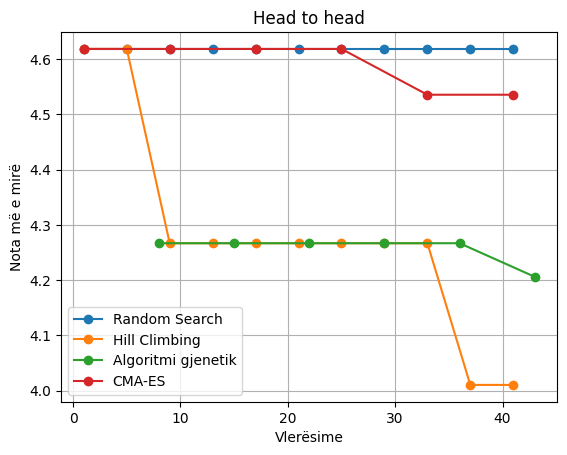

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import multiprocessing as mp
mp.set_start_method("spawn", force=True)
import sys, glob, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
kodi = glob.glob("/kaggle/input/**/algoritmet.py", recursive=True)[0]
sys.path.append(os.path.dirname(kodi)); sys.path.append(os.getcwd())
from algoritmet import *

x0 = np.load(glob.glob("/kaggle/input/**/cmaes_best.npy", recursive=True)[0])
v = Vleresuesi(4)
BUXHETI = 40
algoritmet = {"Random Search": random_search, "Hill Climbing": hill_climbing,
              "Algoritmi gjenetik": algoritmi_gjenetik, "CMA-ES": cmaes}
tabela, best_all = [], (None, 1e9)
for emri, alg in algoritmet.items():
    v.vleresime = 0
    t = time.time()
    xb, fb, hist = alg(v, x0, BUXHETI, seed=0)
    koha = round(time.time() - t)
    tabela.append([emri, round(hist[0][1], 3), round(fb, 3), v.vleresime, koha])
    plt.plot([h[0] for h in hist], [h[1] for h in hist], marker="o", label=emri)
    if fb < best_all[1]: best_all = (xb, fb)
    print(emri, "gati:", round(fb, 3), "në", koha, "s")

df = pd.DataFrame(tabela, columns=["Algoritmi", "Nota fillestare", "Nota finale", "Vlerësime", "Koha (s)"])
print(df.to_string(index=False))
plt.xlabel("Vlerësime"); plt.ylabel("Nota më e mirë"); plt.title("Head to head")
plt.legend(); plt.grid(); plt.savefig("/kaggle/working/krahasimi.png"); plt.show()
np.save("/kaggle/working/krahasimi_best.npy", best_all[0])